In [2]:
import pandas as pd
from pathlib import Path
import copy

# 1: Trial and error

In [3]:
PROJECT_PATH = Path.cwd().parent
METHU_PATH = Path(f"{PROJECT_PATH}/methu_txt")
OUT_PATH = Path(f"{PROJECT_PATH}/out_txt")

print(PROJECT_PATH, "\n", METHU_PATH, "\n", OUT_PATH)

c:\Users\csaba\OneDrive\Asztali gép\info\fisher_informacio 
 c:\Users\csaba\OneDrive\Asztali gép\info\fisher_informacio\methu_txt 
 c:\Users\csaba\OneDrive\Asztali gép\info\fisher_informacio\out_txt


In [4]:
df_tigge = pd.DataFrame(columns=["datum","d_ta","d_tx","d_tn","d_rs"])
df_methu = df_tigge.copy()

In [5]:
print("Betöltöm a Met.hu méréseit...")
with open(f"{METHU_PATH}/BP_d.txt", "r") as file_m:
    sorok = file_m.readlines()
    sorok.pop(0)
    for sor in sorok:
        adatsor = sor.split(";")
        df_methu.loc[len(df_methu)] = [adatsor[0],float(adatsor[1]),float(adatsor[2]), float(adatsor[3]), float(adatsor[4])]
print("Kész!")

print("Betöltöm a Tigge méréseit...")
with open(f"{OUT_PATH}/Budapest_final.txt", "r") as file_t:
    sorok = file_t.readlines()
    sorok.pop(0)
    for sor in sorok:
        adatsor = sor.strip().split(';')
        df_tigge.loc[len(df_tigge)] = [adatsor[0],float(adatsor[1]),float(adatsor[2]), float(adatsor[3]), float(adatsor[4])]
print("Kész!")

Betöltöm a Met.hu méréseit...
Kész!
Betöltöm a Tigge méréseit...
Kész!


In [6]:
print(df_tigge.head(3))
print('--')
print(df_methu.head(3))

        datum  d_ta  d_tx  d_tn  d_rs
0  2006-10-01  17.4  23.4  11.3   0.0
1  2006-10-02  17.6  23.0  12.2   0.0
2  2006-10-03  20.6  24.7  16.5   2.9
--
        datum  d_ta  d_tx  d_tn  d_rs
0  2006-10-01  18.5  24.7  12.9   0.0
1  2006-10-02  19.5  25.1  14.5   0.0
2  2006-10-03  21.1  26.7  15.4   0.0


In [7]:
merged = df_methu.merge(df_tigge, on="datum", how="inner", suffixes=("_tigge", "_methu") )

print("Összeillesztett dataframe:")
merged.head(10)

Összeillesztett dataframe:


,datum,d_ta_tigge,d_tx_tigge,d_tn_tigge,d_rs_tigge,d_ta_methu,d_tx_methu,d_tn_methu,d_rs_methu
0,2006-10-01,18.5,24.7,12.9,0.0,17.4,23.4,11.3,0.0
1,2006-10-02,19.5,25.1,14.5,0.0,17.6,23.0,12.2,0.0
2,2006-10-03,21.1,26.7,15.4,0.0,20.6,24.7,16.5,2.9
3,2006-10-04,17.7,23.9,15.6,0.0,18.4,22.5,14.4,0.2
4,2006-10-05,15.7,19.1,13.2,0.0,15.6,18.7,12.5,0.0
5,2006-10-06,14.4,19.8,10.9,0.0,13.1,17.6,8.5,0.0
6,2006-10-07,14.0,21.2,7.7,0.3,12.4,18.3,6.5,0.1
7,2006-10-08,15.2,19.9,12.2,0.0,13.6,18.3,8.9,0.0
8,2006-10-09,14.2,21.6,8.4,0.0,11.9,18.3,5.5,0.0
9,2006-10-10,14.7,22.2,9.4,0.0,12.5,19.2,5.8,0.0


In [8]:
print("Nézzük a különbségeket:")

for adat in ["d_ta", "d_tx", "d_tn", "d_rs"]:
    print(merged[f"{adat}_methu"],merged[f"{adat}_tigge"])
    merged[f"{adat}_diff"] = merged[f"{adat}_tigge"] - merged[f"{adat}_methu"]

Nézzük a különbségeket:
0       17.4
1       17.6
2       20.6
3       18.4
4       15.6
        ... 
4805    -1.0
4806     4.0
4807     6.7
4808     6.0
4809     3.8
Name: d_ta_methu, Length: 4810, dtype: float64 0       18.5
1       19.5
2       21.1
3       17.7
4       15.7
        ... 
4805     0.1
4806     4.4
4807     8.8
4808     7.5
4809     5.5
Name: d_ta_tigge, Length: 4810, dtype: float64
0       23.4
1       23.0
2       24.7
3       22.5
4       18.7
        ... 
4805     1.5
4806     7.6
4807     9.2
4808     7.9
4809     6.8
Name: d_tx_methu, Length: 4810, dtype: float64 0       24.7
1       25.1
2       26.7
3       23.9
4       19.1
        ... 
4805     2.4
4806     7.3
4807    12.6
4808    10.1
4809     9.9
Name: d_tx_tigge, Length: 4810, dtype: float64
0       11.3
1       12.2
2       16.5
3       14.4
4       12.5
        ... 
4805    -3.6
4806     0.4
4807     4.1
4808     4.1
4809     0.9
Name: d_tn_methu, Length: 4810, dtype: float64 0       12.9
1       14.5


Ez így nem lesz jó, több hiba is előjön, nézzünk egy másik megoldást

In [9]:
def read_file(path):

    df = pd.read_csv(path, sep=";", skiprows=1, header = None, usecols = range(5), names=["datum", "d_ta", "d_tx", "d_tn", "d_rs"] )
    
    df["datum"] = pd.to_datetime(df["datum"])
    for col in ["d_ta", "d_tx", "d_tn", "d_rs"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

In [10]:
df_methu = read_file(f"{METHU_PATH}/BP_d.txt")
df_tigge = read_file(f"{OUT_PATH}/Budapest_final.txt")

print(df_methu.head(3))
print("--")
print(df_tigge.head(3))

       datum  d_ta  d_tx  d_tn  d_rs
0 2006-10-01  18.5  24.7  12.9   0.0
1 2006-10-02  19.5  25.1  14.5   0.0
2 2006-10-03  21.1  26.7  15.4   0.0
--
       datum  d_ta  d_tx  d_tn  d_rs
0 2006-10-01  17.4  23.4  11.3   0.0
1 2006-10-02  17.6  23.0  12.2   0.0
2 2006-10-03  20.6  24.7  16.5   2.9


In [11]:
print(df_methu.isna().sum())
print(df_tigge.isna().sum())

datum    0
d_ta     0
d_tx     0
d_tn     0
d_rs     0
dtype: int64
datum    0
d_ta     0
d_tx     0
d_tn     0
d_rs     0
dtype: int64


In [12]:
merged = df_tigge.merge(df_methu, on="datum", how="inner", suffixes=("_tigge", "_methu"))

for adat in ["d_ta", "d_tx", "d_tn", "d_rs"]:
    merged[f"{adat}_diff"] = merged[f"{adat}_tigge"] - merged[f"{adat}_methu"]

print(f"Tigge: {len(df_tigge)}, Methu: {len(df_methu)}, Összekapcsolt: {len(merged)}")
print("duplikált dátum:", merged["datum"].duplicated().sum())
print(merged.dtypes)
print(merged.filter(like="_diff").describe())

Tigge: 4810, Methu: 5206, Összekapcsolt: 4810
duplikált dátum: 0
datum         datetime64[us]
d_ta_tigge           float64
d_tx_tigge           float64
d_tn_tigge           float64
d_rs_tigge           float64
d_ta_methu           float64
d_tx_methu           float64
d_tn_methu           float64
d_rs_methu           float64
d_ta_diff            float64
d_tx_diff            float64
d_tn_diff            float64
d_rs_diff            float64
dtype: object
         d_ta_diff    d_tx_diff    d_tn_diff    d_rs_diff
count  4810.000000  4810.000000  4810.000000  4810.000000
mean     -1.250021    -1.608046    -1.778295     0.359356
std       1.403003     1.507642     1.508356     3.629564
min      -8.900000    -8.000000   -13.000000   -93.300000
25%      -2.100000    -2.600000    -2.600000     0.000000
50%      -1.300000    -1.700000    -1.700000     0.000000
75%      -0.500000    -0.700000    -0.800000     0.600000
max       6.100000     8.100000     5.300000    34.800000


In [13]:
print(merged.head(10))

       datum  d_ta_tigge  d_tx_tigge  d_tn_tigge  d_rs_tigge  d_ta_methu  \
0 2006-10-01        17.4        23.4        11.3         0.0        18.5   
1 2006-10-02        17.6        23.0        12.2         0.0        19.5   
2 2006-10-03        20.6        24.7        16.5         2.9        21.1   
3 2006-10-04        18.4        22.5        14.4         0.2        17.7   
4 2006-10-05        15.6        18.7        12.5         0.0        15.7   
5 2006-10-06        13.1        17.6         8.5         0.0        14.4   
6 2006-10-07        12.4        18.3         6.5         0.1        14.0   
7 2006-10-08        13.6        18.3         8.9         0.0        15.2   
8 2006-10-09        11.9        18.3         5.5         0.0        14.2   
9 2006-10-10        12.5        19.2         5.8         0.0        14.7   

   d_tx_methu  d_tn_methu  d_rs_methu  d_ta_diff  d_tx_diff  d_tn_diff  \
0        24.7        12.9         0.0       -1.1       -1.3       -1.6   
1        25.1  

In [14]:
merged.describe()

,datum,d_ta_tigge,d_tx_tigge,d_tn_tigge,d_rs_tigge,d_ta_methu,d_tx_methu,d_tn_methu,d_rs_methu,d_ta_diff,d_tx_diff,d_tn_diff,d_rs_diff
count,4810,4810.000000,4810.000000,4810.00000,4810.000000,4810.000000,4810.000000,4810.000000,4810.000000,4810.000000,4810.000000,4810.000000,4810.000000
mean,2013-09-23 13:02:16.216216,11.844865,16.324324,7.36578,1.836590,13.094886,17.932370,9.144075,1.477235,-1.250021,-1.608046,-1.778295,0.359356
min,2006-10-01 00:00:00,-13.400000,-9.300000,-20.20000,0.000000,-10.700000,-8.900000,-13.700000,0.000000,-8.900000,-8.000000,-13.000000,-93.300000
25%,2010-03-17 06:00:00,4.700000,8.300000,1.10000,0.000000,6.100000,9.700000,3.300000,0.000000,-2.100000,-2.600000,-2.600000,0.000000
50%,2013-07-01 12:00:00,12.300000,17.000000,7.50000,0.200000,13.500000,18.600000,9.400000,0.000000,-1.300000,-1.700000,-1.700000,0.000000
75%,2017-08-15 18:00:00,19.200000,24.200000,14.20000,1.700000,20.100000,26.000000,15.300000,0.475000,-0.500000,-0.700000,-0.800000,0.600000
max,2020-12-31 00:00:00,32.400000,39.500000,25.70000,46.100000,33.100000,40.100000,26.000000,115.400000,6.100000,8.100000,5.300000,34.800000
std,NaN,8.703305,9.685322,7.96685,3.916223,8.566121,9.841617,7.478967,4.531483,1.403003,1.507642,1.508356,3.629564


Vegyük ki egy külön dataframe-be csak az eltéréseket.

In [15]:
diffs = merged[["datum", "d_ta_diff", "d_tx_diff", "d_tn_diff", "d_rs_diff"]].copy()
diffs.columns = ["datum", "d_ta", "d_tx", "d_tn", "d_rs"]   # a _diff végződés fölösleges, a tábla neve már jelzi
diffs = diffs.set_index("datum").sort_index()

print(diffs.head(10))

            d_ta  d_tx  d_tn  d_rs
datum                             
2006-10-01  -1.1  -1.3  -1.6   0.0
2006-10-02  -1.9  -2.1  -2.3   0.0
2006-10-03  -0.5  -2.0   1.1   2.9
2006-10-04   0.7  -1.4  -1.2   0.2
2006-10-05  -0.1  -0.4  -0.7   0.0
2006-10-06  -1.3  -2.2  -2.4   0.0
2006-10-07  -1.6  -2.9  -1.2  -0.2
2006-10-08  -1.6  -1.6  -3.3   0.0
2006-10-09  -2.3  -3.3  -2.9   0.0
2006-10-10  -2.2  -3.0  -3.6   0.0


Probáljunk vizualizálni!

In [16]:
import matplotlib.pyplot as plt

In [17]:
m = diffs.loc["2007-06"]
print(m)

            d_ta  d_tx  d_tn  d_rs
datum                             
2007-06-01  -2.6  -3.1  -1.8   0.9
2007-06-02  -2.5  -3.5  -1.8  -3.1
2007-06-03  -1.9  -2.3  -2.3   2.6
2007-06-04  -2.7  -2.1  -3.2  -5.8
2007-06-05  -1.3  -3.5  -1.9  -1.6
2007-06-06  -0.6  -1.8  -2.4   3.5
2007-06-07  -3.3  -4.2  -3.3   2.1
2007-06-08  -2.9  -2.2  -3.1   0.9
2007-06-09  -2.3  -2.3  -3.0   0.0
2007-06-10  -2.0  -4.9  -1.0   2.1
2007-06-11  -2.5  -3.0  -1.2   4.0
2007-06-12  -2.9  -1.6  -3.1   1.0
2007-06-13  -2.9  -4.6  -2.9   4.5
2007-06-14  -2.6  -3.6  -1.2   2.8
2007-06-15  -3.3  -3.1  -1.5   2.0
2007-06-16  -0.1  -3.3   0.4   0.0
2007-06-17  -2.6  -2.8  -2.0   0.1
2007-06-18  -1.9  -1.7  -2.2   0.9
2007-06-19  -3.3  -2.6  -3.2   2.1
2007-06-20  -2.4  -1.4  -2.5   0.0
2007-06-21   1.3  -0.1  -1.3 -15.2
2007-06-22  -0.3  -0.7   0.2   1.3
2007-06-23  -0.3  -1.7  -0.9   0.0
2007-06-24  -1.1  -1.0  -1.9   0.0
2007-06-25  -0.9  -0.4   0.9   0.0
2007-06-26   3.4   0.3   0.0   0.1
2007-06-27   0.0   0

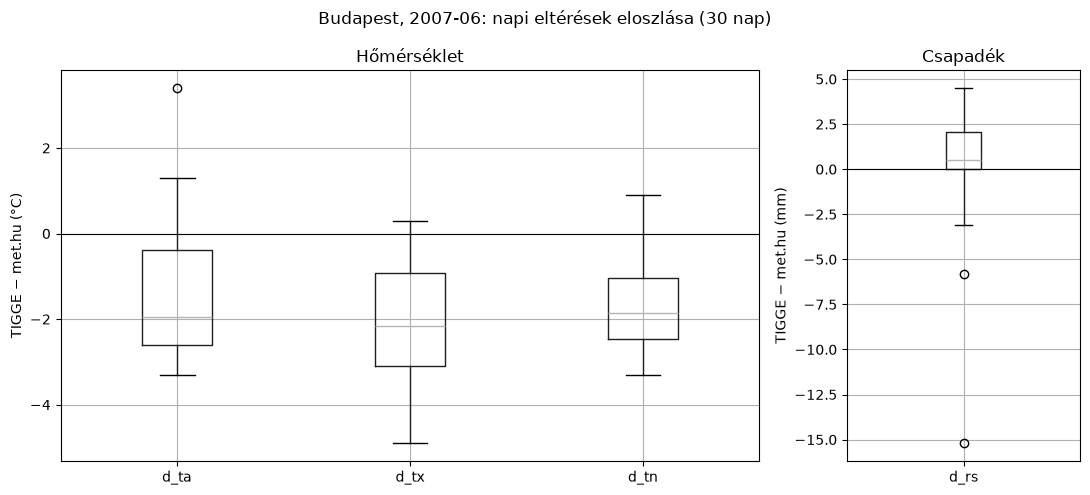

In [18]:
fig, (ax_t, ax_p) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [3, 1]})

m[["d_ta", "d_tx", "d_tn"]].boxplot(ax=ax_t)
ax_t.axhline(0, color="black", lw=0.8)
ax_t.set_ylabel("TIGGE − met.hu (°C)")
ax_t.set_title("Hőmérséklet")

m[["d_rs"]].boxplot(ax=ax_p)
ax_p.axhline(0, color="black", lw=0.8)
ax_p.set_ylabel("TIGGE − met.hu (mm)")
ax_p.set_title("Csapadék")

fig.suptitle(f"Budapest, 2007-06: napi eltérések eloszlása ({len(m)} nap)")
plt.tight_layout()
plt.show()

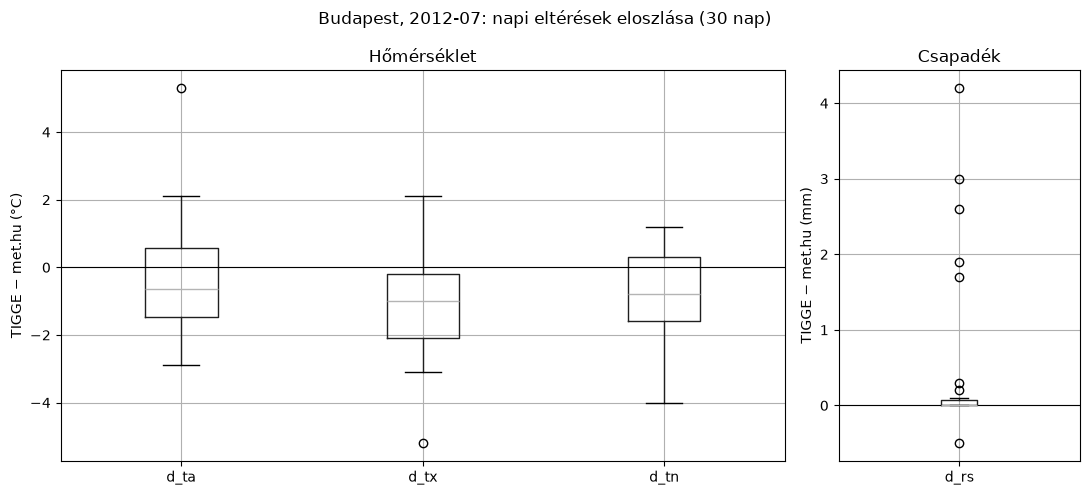

In [19]:
m = diffs.loc["2012-09"]

fig, (ax_t, ax_p) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [3, 1]})

m[["d_ta", "d_tx", "d_tn"]].boxplot(ax=ax_t)
ax_t.axhline(0, color="black", lw=0.8)
ax_t.set_ylabel("TIGGE − met.hu (°C)")
ax_t.set_title("Hőmérséklet")

m[["d_rs"]].boxplot(ax=ax_p)
ax_p.axhline(0, color="black", lw=0.8)
ax_p.set_ylabel("TIGGE − met.hu (mm)")
ax_p.set_title("Csapadék")

fig.suptitle(f"Budapest, 2012-07: napi eltérések eloszlása ({len(m)} nap)")
plt.tight_layout()

In [20]:

print("Függvényesítsük!")

def plot_month(diffs, year, month, city="Budapest"):
    # Szűrés külön változóba
    m = diffs[
        (diffs.index.year == year) &
        (diffs.index.month == month)
    ]

    if m.empty:
        print("A hónapról nincs adatunk!")
        return

    fig, (ax_t, ax_p) = plt.subplots(
        1, 2,
        figsize=(11, 5),
        gridspec_kw={"width_ratios": [3, 1]}
    )

    m[["d_ta", "d_tx", "d_tn"]].boxplot(ax=ax_t)
    ax_t.axhline(0, color="black", lw=0.8)
    ax_t.set_ylabel("TIGGE − met.hu (°C)")
    ax_t.set_title("Hőmérséklet")

    m[["d_rs"]].boxplot(ax=ax_p)
    ax_p.axhline(0, color="black", lw=0.8)
    ax_p.set_ylabel("TIGGE − met.hu (mm)")
    ax_p.set_title("Csapadék")

    fig.suptitle(
        f"{city}, {year}-{month:02d}: "
        f"napi eltérések eloszlása ({len(m)} nap)"
    )

    plt.tight_layout()
    plt.show()


Függvényesítsük!


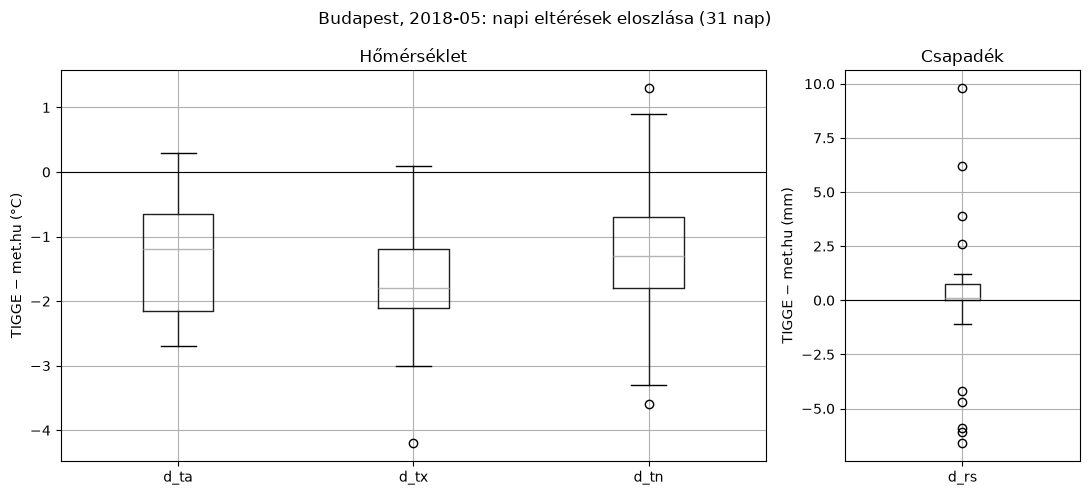

In [21]:
plot_month(diffs,2018,5)

Na ez tök jó, releváns dolgokat látunk. 

Célünk az, hogy az eltéréseket összesítve és városonként is tudjuk átláthatóan mérni. Bevezetünk erre egy vagy több metrikát!

MAE = Mean Average Error, az abszolút eltérések átlaga egy napon

RMSE = Root Mean Squared Error,  mint az MAE, de a nagy kiugrásokat jobban bünteti

Ami még fontos lesz nekünk, az az eltérések szórása. Észrevehetünk egy állandó eltolást, ami következhet abból hogy a rácspont nem az állomás, de ha például egyik napon -3 a mások napon +5 az eltérés, az már az előrejelzés megbízhatatlanságáról szól.

In [22]:
diffs.describe()

,d_ta,d_tx,d_tn,d_rs
count,4810.000000,4810.000000,4810.000000,4810.000000
mean,-1.250021,-1.608046,-1.778295,0.359356
std,1.403003,1.507642,1.508356,3.629564
min,-8.900000,-8.000000,-13.000000,-93.300000
25%,-2.100000,-2.600000,-2.600000,0.000000
50%,-1.300000,-1.700000,-1.700000,0.000000
75%,-0.500000,-0.700000,-0.800000,0.600000
max,6.100000,8.100000,5.300000,34.800000


In [23]:
print(f"Budapest MAE napi középhőmérséklet: {float(diffs["d_ta"].abs().mean())}")
print(f"Budapest RMSE napi középhőmérséklet: {float((diffs["d_ta"] ** 2).mean() ** 0.5) }")
print(f"Szórás: {float(diffs["d_ta"].std())}")

Budapest MAE napi középhőmérséklet: 1.5582536382536385
Budapest RMSE napi középhőmérséklet: 1.8789787999233334
Szórás: 1.403003417569311


In [24]:
for col in ["d_ta","d_tx"]:
    print(f"{col}: {diffs[col].abs().mean()}")

d_ta: 1.5582536382536385
d_tx: 1.852869022869023


Konzultáció után célirányosan haladunk tovább.

In [25]:
print(merged.head())

       datum  d_ta_tigge  d_tx_tigge  d_tn_tigge  d_rs_tigge  d_ta_methu  \
0 2006-10-01        17.4        23.4        11.3         0.0        18.5   
1 2006-10-02        17.6        23.0        12.2         0.0        19.5   
2 2006-10-03        20.6        24.7        16.5         2.9        21.1   
3 2006-10-04        18.4        22.5        14.4         0.2        17.7   
4 2006-10-05        15.6        18.7        12.5         0.0        15.7   

   d_tx_methu  d_tn_methu  d_rs_methu  d_ta_diff  d_tx_diff  d_tn_diff  \
0        24.7        12.9         0.0       -1.1       -1.3       -1.6   
1        25.1        14.5         0.0       -1.9       -2.1       -2.3   
2        26.7        15.4         0.0       -0.5       -2.0        1.1   
3        23.9        15.6         0.0        0.7       -1.4       -1.2   
4        19.1        13.2         0.0       -0.1       -0.4       -0.7   

   d_rs_diff  
0        0.0  
1        0.0  
2        2.9  
3        0.2  
4        0.0  


# 2: Delta számítások

In [28]:
DELTA_PATH = Path(f"{PROJECT_PATH}/delta_methods")
DELTA_PATH.mkdir(exist_ok=True)

In [26]:
def read_daily(path):
    df = pd.read_csv(path, sep=";", skiprows=1, header=None,
                     usecols=range(5), names=["datum", "d_ta", "d_tx", "d_tn", "d_rs"])
    df["datum"] = pd.to_datetime(df["datum"])
    for col in ["d_ta", "d_tx", "d_tn", "d_rs"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

Ez a módszer egy napi, dimenzió nélküli hibaszám, ami a négy mennyiség eltéréset egy közös skálára hozza
1: Abszolút hiba mennyiségenént | Tigge - Methu |

2: Osztás a mérés szórásával: Ezt az abszolút hibát elosztja a met.hu mérés szórásával, ami az adott városra, az adott mennyiségre és az adott naptári hónapra vonatkozik.

3: A 4 szám átlaga, a négy normalizált hibát átlagolja

In [29]:
variables = ["d_ta", "d_tx", "d_tn", "d_rs"]

methu_files = {
    "Budapest": "BP_d.txt",
    "Debrecen": "DE_d.txt",
    "Pécs": "PE_d.txt",
    "Szeged": "SZE_d.txt",
    "Szombathely": "SZO_d.txt",
}

for city, methu_file in methu_files.items():
    t = read_daily(f"{OUT_PATH}/{city}_final.txt")
    o = read_daily(f"{METHU_PATH}/{methu_file}")

    sigma = o.groupby(o["datum"].dt.month)[variables].std()

    m = t.merge(o, on = "datum", how = "inner", suffixes=("_tigge","_methu"))
    month = m["datum"].dt.month

    norm_error = pd.DataFrame(index=m.index)

    for v in variables:
        error = (m[f"{v}_tigge"] - m[f"{v}_methu"]).abs()
        norm_error[v] = error / month.map(sigma[v])

    m["delta"] = norm_error.mean(axis=1, skipna=False).round(3)

    out = m[["datum"] + [f"{v}_{s}" for v in variables for s in ("tigge", "methu")] + ["delta"]]
    out = out.rename(columns={"datum": "#datum"})
    out.to_csv(f"{DELTA_PATH}/{city}_osszevetes.txt", sep=";", index=False, date_format="%Y-%m-%d")

    print(city, len(out), "sor, átlagos delta:", round(m["delta"].mean(), 3))

Budapest 4810 sor, átlagos delta: 0.423
Debrecen 4810 sor, átlagos delta: 0.297
Pécs 4810 sor, átlagos delta: 0.282
Szeged 4810 sor, átlagos delta: 0.329
Szombathely 4810 sor, átlagos delta: 0.334
